**Análisis Exploratorio y Manipulación de Datos**

In [ ]:
# Cargamos librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [23]:
# Cargamos la base de datos
ruta = ('/content/drive/MyDrive/Colab Notebooks/Social_media_impact_on_life.xlsx')
df_redes_sociales = pd.read_excel(ruta)
df_redes_sociales.head()

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


* **Student_ID:** Identificador único asignado a cada estudiante registrado.   

* **Age:** Edad del estudiante.   

* **Gender:** Género del estudiante.   

* **Academic_Level:** Nivel académico actual (por ejemplo, secundaria o estudios de pregrado).   

* **Primary_Platform:** Plataforma digital que el estudiante utiliza con mayor frecuencia (como Snapchat, Instagram, TikTok, YouTube, LinkedIn, Reddit o X/Twitter).   

* **Daily_Usage_Time:** Tiempo de uso diario de las plataformas digitales expresado en horas.   

* **Weekend_Extra:** Métrica correspondiente al uso adicional de tecnología durante los fines de semana.   

* **Device_Type:** Dispositivo principal empleado para el acceso digital (por ejemplo, teléfono inteligente o tableta).   

* **Sleep_Duration:** Duración promedio del sueño expresada en horas.   

* **Sleep_Quality:** Calificación cuantitativa de la calidad del sueño.   

* **Late_Night_Usage:** Indicador lógico (Verdadero o Falso) sobre si el estudiante utiliza dispositivos tarde en la noche.   

* **Social_Comparison:** Frecuencia con la que el estudiante experimenta comparación social (por ejemplo, siempre, a veces, frecuentemente, nunca, raramente).   

* **Perceived_Stress:** Puntuación o métrica correspondiente al nivel de estrés percibido.   

* **Mental_Health:** Puntuación relacionada con el estado general de salud mental.   

* **Academic_Performance:** Calificación o puntaje que mide el rendimiento académico.   

* **Overall_Impact:** Variable objetivo (Target) que clasifica el impacto general de estos hábitos en tres categorías: Beneficial, Neutral o Negative.   

Identifica correctamente la cantidad de valores faltantes (NA) en las variables cuantitativas seleccionadas.

In [24]:
print("--- CONTEO DE MISSING VALUES POR COLUMNA ---")
print(df_redes_sociales.isna().sum())

--- CONTEO DE MISSING VALUES POR COLUMNA ---
Student_ID                      0
Age                             0
Gender                          0
Academic_Level                  0
Primary_Platform                0
Daily_Usage_Hours               0
Weekend_Extra_Hours             0
Device_Type                     0
Sleep_Duration_Hours            0
Sleep_Quality_Score             0
Late_Night_Usage                0
Social_Comparison_Frequency     0
Perceived_Stress_Score         46
Mental_Health_Index             0
Academic_Performance_GPA       85
Overall_Impact                  0
dtype: int64


Imputación

KeyError: 'Perceived_Stress_Score_Media'

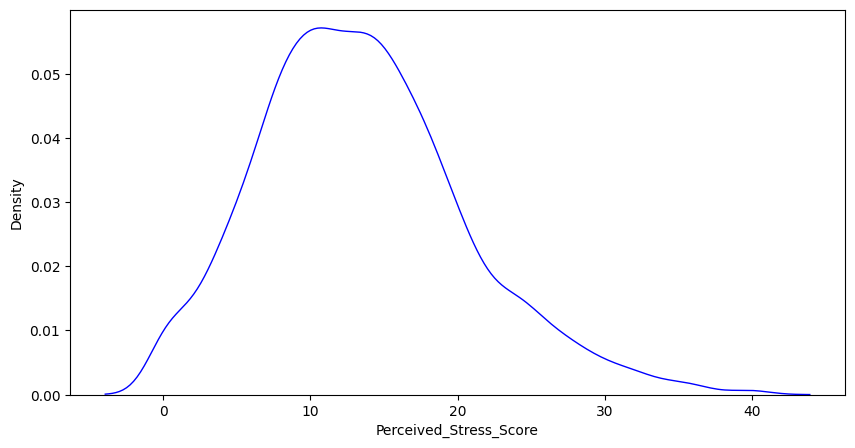

In [25]:
# df_imputado = df_redes_sociales.copy()  <-- QUITAR O COMENTAR ESTA LÍNEA EN LA SEGUNDA CELDA

# ==============================================================================
# Imputación por media
# ==============================================================================
df_imputado['Academic_Performance_GPA_Media'] = df_imputado['Academic_Performance_GPA'].fillna(
    df_imputado['Academic_Performance_GPA'].mean())

# ==============================================================================
# Imputación por mediana
# ==============================================================================
df_imputado['Perceived_Stress_Score_Mediana'] = df_imputado['Perceived_Stress_Score'].fillna(
    df_imputado['Perceived_Stress_Score'].median())

# ==============================================================================
# Imputación por Grupo
# ==============================================================================
df_imputado['Perceived_Stress_Score_Grupo'] = df_imputado.groupby('Gender')['Perceived_Stress_Score'].transform(
    lambda x: x.fillna(x.mean())
)

# ==============================================================================
# Imputación K - vecinos cercanos
# ==============================================================================
from sklearn.impute import KNNImputer
# Seleccionar variables numéricas de apoyo para calcular la similitud entre estudiantes
columnas_knn = [
    'Age',
    'Daily_Usage_Hours',
    'Weekend_Extra_Hours',
    'Sleep_Duration_Hours',
    'Sleep_Quality_Score',
    'Perceived_Stress_Score',
    'Mental_Health_Index',
    'Academic_Performance_GPA'
]
# Aplicamos el KNNImputer temporalmente a las columnas numéricas
knn_imputer = KNNImputer(n_neighbors=5)
df_temp = pd.DataFrame(
    knn_imputer.fit_transform(df_imputado[columnas_knn]),
    columns=columnas_knn,
    index=df_imputado.index
)
# Creamos la columna extra con los datos imputados por KNN
df_imputado['Perceived_Stress_Score_KNN'] = df_temp['Perceived_Stress_Score']

# Comparación Visual de los 4 métodos
plt.figure(figsize=(10, 5))
sns.kdeplot(df_redes_sociales['Perceived_Stress_Score'], label='Original', color='blue', linewidth=1)
sns.kdeplot(df_imputado['Perceived_Stress_Score_Media'], label='Imputación por Media', color='red', linestyle='--')
sns.kdeplot(df_imputado['Perceived_Stress_Score_Mediana'], label='Imputación por Mediana', color='green', linestyle='--')
sns.kdeplot(df_imputado['Perceived_Stress_Score_Grupo'], label='Imputación por Grupo', color='purple', linestyle='--')
sns.kdeplot(df_imputado['Perceived_Stress_Score_KNN'], label='Imputación por KNN', color='orange', linestyle='--')
plt.title('Comparación de Distribución de Perceived_Stress_Score con Imputaciones')
plt.xlabel('Perceived_Stress_Score')
plt.ylabel('Densidad')
plt.legend()
plt.tight_layout()
plt.show()

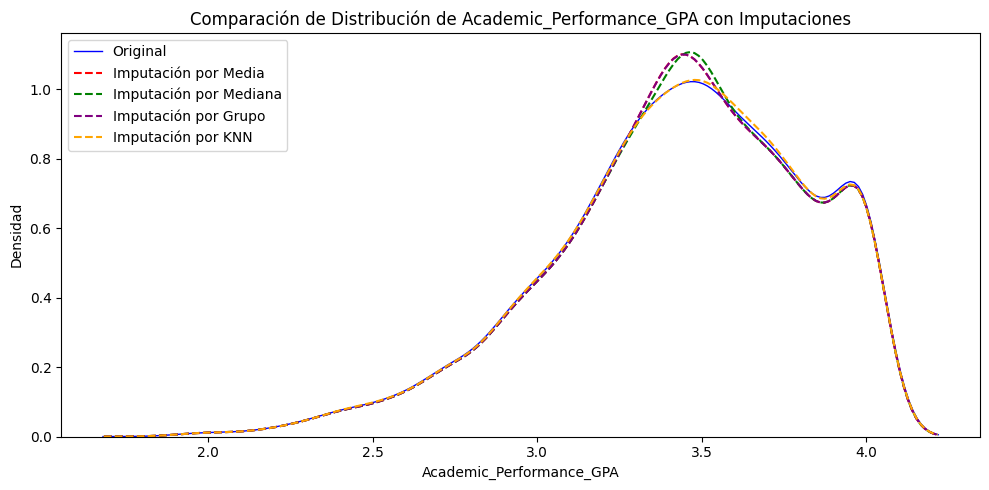

In [ ]:
df_imputado = df_redes_sociales.copy()

# ==============================================================================
# Imputación por media
# ==============================================================================
df_imputado['Academic_Performance_GPA_Media'] = df_imputado['Academic_Performance_GPA'].fillna(
    df_imputado['Academic_Performance_GPA'].mean())

# ==============================================================================
# Imputación por mediana
# ==============================================================================
df_imputado['Academic_Performance_GPA_Mediana'] = df_imputado['Academic_Performance_GPA'].fillna(
    df_imputado['Academic_Performance_GPA'].median())

# ==============================================================================
# Imputación por Grupo
# ==============================================================================
df_imputado['Academic_Performance_GPA_Grupo'] = df_imputado.groupby('Gender')['Academic_Performance_GPA'].transform(
    lambda x: x.fillna(x.mean())
)

# ==============================================================================
# Imputación K - vecinos cercanos
# ==============================================================================
from sklearn.impute import KNNImputer
# Seleccionar variables numéricas de apoyo para calcular la similitud entre estudiantes
columnas_knn = [
    'Age',
    'Daily_Usage_Hours',
    'Weekend_Extra_Hours',
    'Sleep_Duration_Hours',
    'Sleep_Quality_Score',
    'Perceived_Stress_Score',
    'Mental_Health_Index',
    'Academic_Performance_GPA'
]
# Aplicamos el KNNImputer temporalmente a las columnas numéricas
knn_imputer = KNNImputer(n_neighbors=5)
df_temp = pd.DataFrame(
    knn_imputer.fit_transform(df_imputado[columnas_knn]),
    columns=columnas_knn,
    index=df_imputado.index
)
# Creamos la columna extra con los datos imputados por KNN
df_imputado['Academic_Performance_GPA_KNN'] = df_temp['Academic_Performance_GPA']

# Comparación Visual de los 4 métodos
plt.figure(figsize=(10, 5))
sns.kdeplot(df_redes_sociales['Academic_Performance_GPA'], label='Original', color='blue', linewidth=1)
sns.kdeplot(df_imputado['Academic_Performance_GPA_Media'], label='Imputación por Media', color='red', linestyle='--')
sns.kdeplot(df_imputado['Academic_Performance_GPA_Mediana'], label='Imputación por Mediana', color='green', linestyle='--')
sns.kdeplot(df_imputado['Academic_Performance_GPA_Grupo'], label='Imputación por Grupo', color='purple', linestyle='--')
sns.kdeplot(df_imputado['Academic_Performance_GPA_KNN'], label='Imputación por KNN', color='orange', linestyle='--')
plt.title('Comparación de Distribución de Academic_Performance_GPA con Imputaciones')
plt.xlabel('Academic_Performance_GPA')
plt.ylabel('Densidad')
plt.legend()
plt.tight_layout()
plt.show()

# **Análisis Exploratorio**

KeyError: 'Perceived_Stress_Score_KNN'

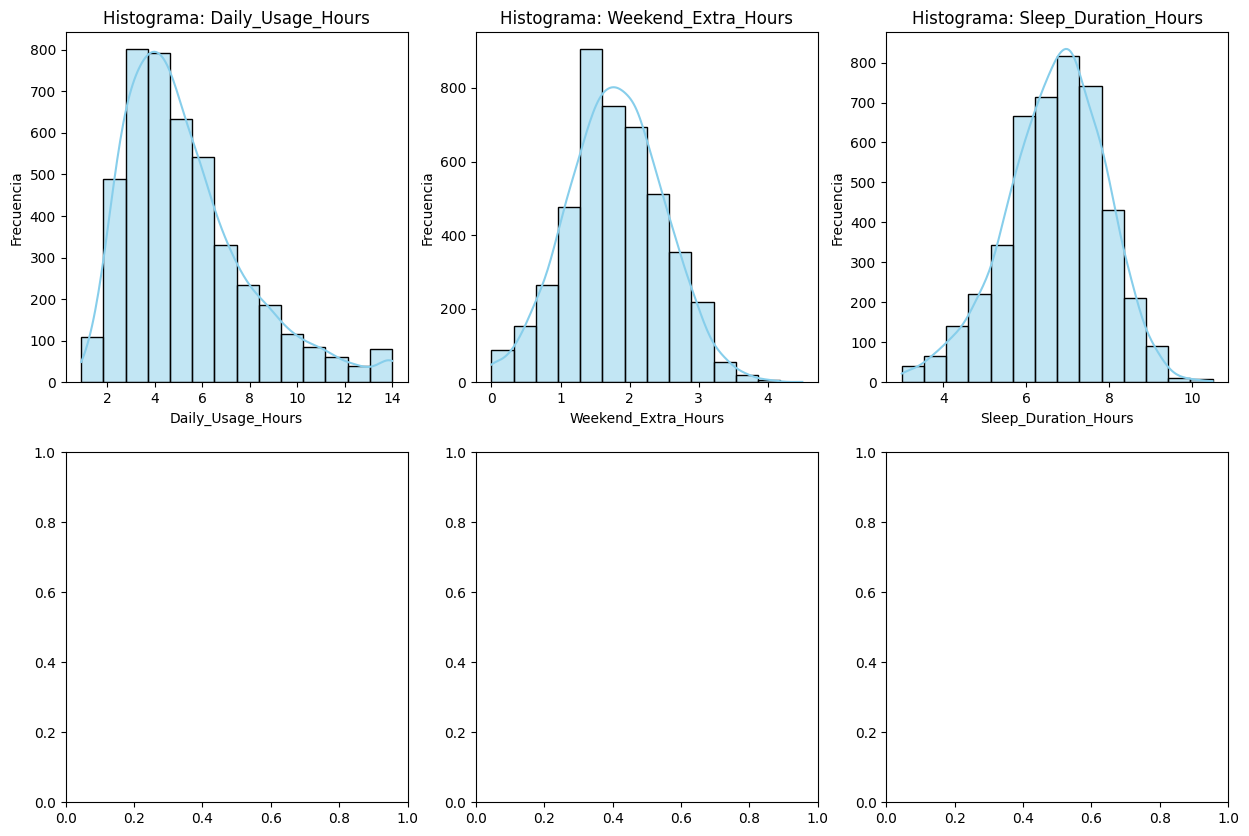

In [ ]:
# 1. Definición de las variables clasificadas.
variables_continuas = [
    'Daily_Usage_Hours',
    'Weekend_Extra_Hours',
    'Sleep_Duration_Hours',
    'Perceived_Stress_Score_KNN',
    'Mental_Health_Index',
    'Academic_Performance_GPA_KNN'
]

variables_discretas = [
    'Age',
    'Sleep_Quality_Score'
]

variables_cualitativas = [
    'Gender',
    'Academic_Level',
    'Primary_Platform',
    'Device_Type',
    'Late_Night_Usage',
    'Social_Comparison_Frequency',
    'Overall_Impact'
]

# ==============================================================================
# HISTOGRAMAS PARA VARIABLES CONTINUAS (Subplots)
# ==============================================================================

fig_cont, axes_cont = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))
axes_cont = axes_cont.flatten()  # <-- Solución: aplanar el arreglo de ejes

for i, var in enumerate(variables_continuas):
    sns.histplot(df_imputado[var].dropna(), bins = 'sturges', kde=True, color='skyblue', ax=axes_cont[i])
    axes_cont[i].set_title(f'Histograma: {var}')
    axes_cont[i].set_xlabel(var)
    axes_cont[i].set_ylabel('Frecuencia')

fig_cont.tight_layout()
plt.show()

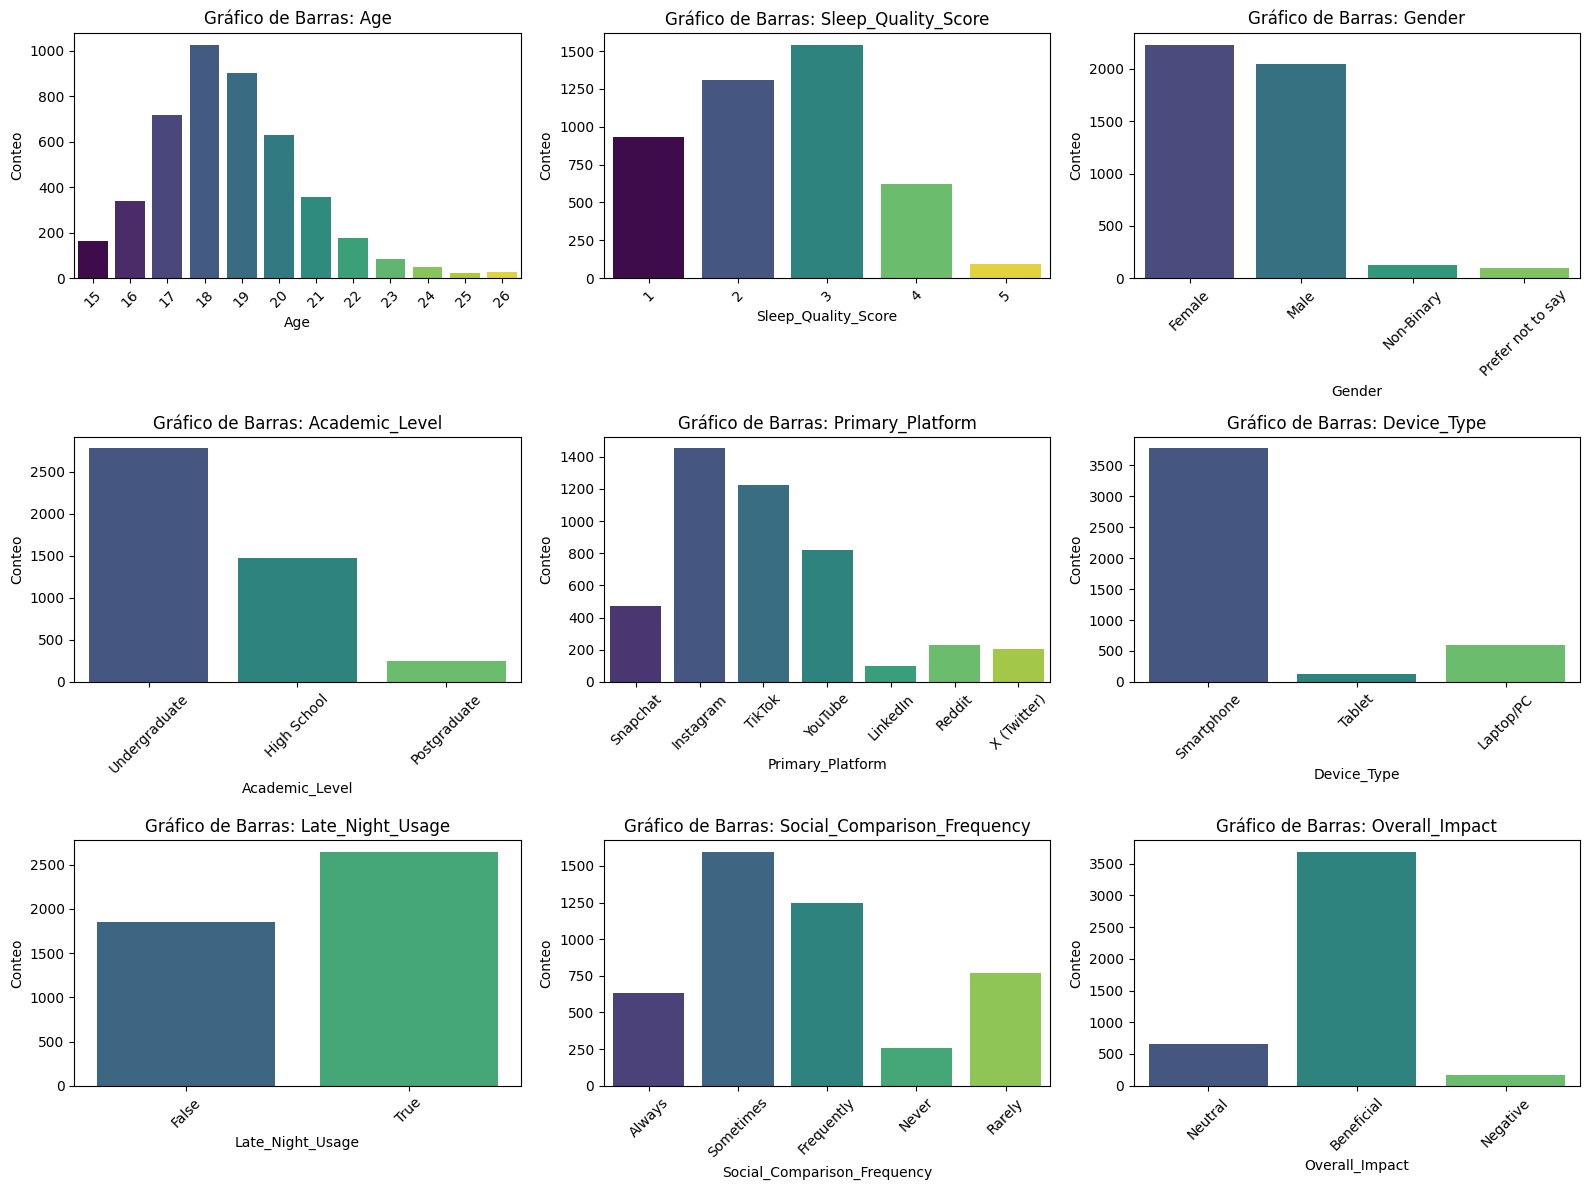

In [ ]:
# ==============================================================================
# GRÁFICOS DE BARRAS PARA VARIABLES DISCRETAS Y CUALITATIVAS (Subplots)
# ==============================================================================

todas_barras = variables_discretas + variables_cualitativas
fig_bar, axes_bar = plt.subplots(nrows=3, ncols=3, figsize=(16, 12))
axes_bar = axes_bar.flatten()

for i, var in enumerate(todas_barras):
    sns.countplot(
        data=df_imputado,
        x=var,
        hue=var,
        legend=False,
        palette='viridis',
        ax=axes_bar[i]
    )
    axes_bar[i].set_title(f'Gráfico de Barras: {var}')
    axes_bar[i].set_xlabel(var)
    axes_bar[i].set_ylabel('Conteo')
    axes_bar[i].tick_params(axis='x', rotation=45)

fig_bar.tight_layout()
plt.show()

KeyError: 'Perceived_Stress_Score_KNN'

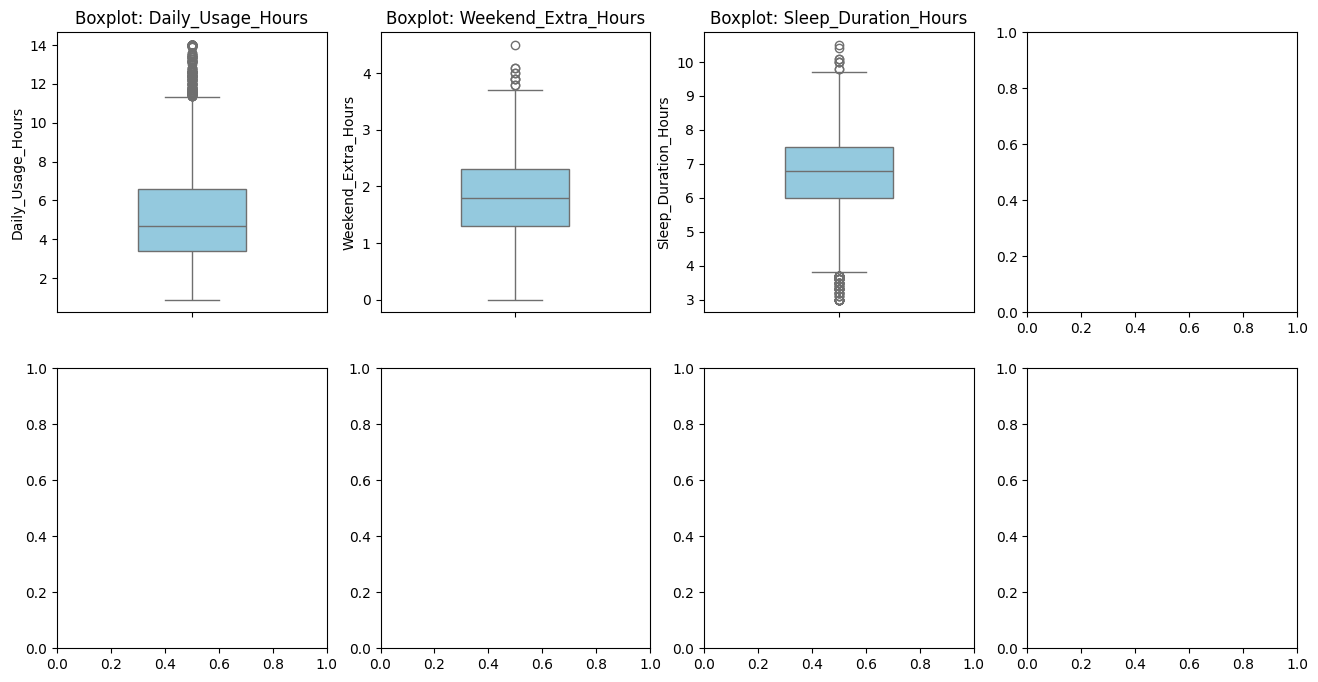

In [ ]:
# Unir las variables continuas y discretas para abarcar todas las numéricas
variables_numericas = variables_continuas + variables_discretas

# Configurar la cuadrícula de subplots (por ejemplo, 2 filas y 4 columnas para 8 variables)
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16, 8))
axes = axes.flatten()

# Ciclo para generar los diagramas de caja y bigotes
for i, var in enumerate(variables_numericas):
    sns.boxplot(
        y=df_imputado[var],
        color="skyblue",
        width=0.4,
        ax=axes[i]
    )
    axes[i].set_title(f"Boxplot: {var}")
    axes[i].set_ylabel(var)

plt.tight_layout()
plt.show()

In [ ]:
def detectar_outliers_iqr(base_datos, columna):
    Q1 = base_datos[columna].quantile(0.25)
    Q3 = base_datos[columna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    # Filtrar valores fuera de los límites
    condicion_inferior = base_datos[columna] < limite_inferior
    condicion_superior = base_datos[columna] > limite_superior

    # Guardamos esos valores en una variable
    outliers = base_datos[np.logical_or(condicion_inferior, condicion_superior)]

    print("="*60)
    print("Análisis de Outliers (IQR) para la variable", columna)
    print("Q1 (25%):", round(Q1, 2), ", Q3 (75%):", round(Q3, 2), ", IQR:", round(IQR, 2))
    print("Límite Inferior:", round(limite_inferior, 2))
    print("Límite Superior:", round(limite_superior, 2))
    print("Número total de valores atípicos:", len(outliers))
    print("Porcentaje de datos atípicos:", round((len(outliers) / len(base_datos)) * 100, 2), "%")

    return outliers

# Unir las variables continuas y discretas para evaluar todas las numéricas
variables_numericas = variables_continuas + variables_discretas

# Diccionario para almacenar los outliers de cada variable mediante un ciclo for
diccionario_outliers = {}

for var in variables_numericas:
    diccionario_outliers[var] = detectar_outliers_iqr(df_imputado, var)

Análisis de Outliers (IQR) para la variable Daily_Usage_Hours
Q1 (25%): 3.4 , Q3 (75%): 6.6 , IQR: 3.2
Límite Inferior: -1.4
Límite Superior: 11.4
Número total de valores atípicos: 162
Porcentaje de datos atípicos: 3.6 %
Análisis de Outliers (IQR) para la variable Weekend_Extra_Hours
Q1 (25%): 1.3 , Q3 (75%): 2.3 , IQR: 1.0
Límite Inferior: -0.2
Límite Superior: 3.8
Número total de valores atípicos: 10
Porcentaje de datos atípicos: 0.22 %
Análisis de Outliers (IQR) para la variable Sleep_Duration_Hours
Q1 (25%): 6.0 , Q3 (75%): 7.5 , IQR: 1.5
Límite Inferior: 3.75
Límite Superior: 9.75
Número total de valores atípicos: 72
Porcentaje de datos atípicos: 1.6 %


KeyError: 'Perceived_Stress_Score_KNN'

# **Manipulación de Datos en Python con Pandas**

**Pandas** es la librería fundamental en Python para la manipulación, limpieza y análisis exploratorio de datos. A diferencia de `dplyr` en R que utiliza funciones independientes y el operador pipe (`%>%`), Pandas opera mediante métodos sobre objetos de tipo `DataFrame` usando la notación de punto (`df.metodo()`).

---

### **Carga de librerías e importación de datos**

# Principales equivalencias de funciones: Pandas (`Python`) vs dplyr (`R`)

---

### 1. `select()` → Selección de columnas
En Pandas seleccionamos columnas mediante corchetes `df['columna']` o listas de columnas `df[['col1', 'col2']]`.

In [ ]:
# Seleccionamos solo la columna "Primary_Platform"
df_primary_platform = df_imputado[["Primary_Platform"]]
# Nota: Al usar doble corchete obtenemos un Data Frame
print("--- Primeras observaciones de la variable Primary_Platform ---")
print(df_primary_platform.head())
print("\n" + "="*90, "\n")

# De forma alternativa: Un solo corchete [ ] devuelve una 'Series'
df_primary_platform1 = df_imputado["Primary_Platform"]
print("--- Primeras observaciones de la variable Primary_Platform ---")
print(df_primary_platform1.head())
print("\n" + "="*90, "\n")

# Seleccionamos dos columnas: 'Primary_Platform' y 'Gender'
df_primary_platform_gender = df_imputado[["Primary_Platform", "Gender"]]
print("--- Primeras observaciones de las variables Primary_Platform y Gender ---")
print(df_primary_platform_gender.head())
print("\n" + "="*90, "\n")

# Seleccionar por índice de columna (primeras 3 columnas: posiciones 0, 1 y 2)
# Se utiliza .iloc[:, [índices]]
df_primary_platform_gender_iloc = df_imputado.iloc[:, 0:3]
print("--- Primeras observaciones de las variables Primary_Platform y Gender ---")
print(df_primary_platform_gender_iloc.head())

### 2. `filter()` → Filtrado de filas (Indexación booleana)
En Pandas el filtrado de filas se realiza pasando una condición lógica dentro de corchetes `df[condicion]`.

In [ ]:
# --- Filtrar por Device_Type ---

# Primero contamos el número de datos en cada categoría.
print("--- Conteo de categorías de la variable Device_Type ---")
print(df_imputado["Device_Type"].value_counts())
print("\n" + "="*90, "\n")

smartphones = df_imputado[df_imputado["Device_Type"] == "Smartphone"]
print("--- Primeras observaciones de los Smartphones ---")
display(smartphones.head())
print("\n" + "="*90, "\n")

laptop_pc = df_imputado[df_imputado["Device_Type"] == "Laptop/PC"]
print("--- Primeras observaciones de las Laptops/PCs ---")
display(laptop_pc.head())
print("\n" + "="*90, "\n")

tablet = df_imputado[df_imputado["Device_Type"] == "Tablet"]
print("--- Primeras observaciones de las Tablets ---")
display(tablet.head())
print("\n" + "="*90, "\n")

### 3. `arrange()` → Ordenamiento con `sort_values()`
Para ordenar las filas según una o más columnas, utilizamos el método `.sort_values()`.

In [ ]:
# --- Ordenar por edad, de menor a mayor (Ascendente) ---
arrange_age = df_imputado.sort_values(by="Age")
display(arrange_age.head())

# --- Ordenar por Daily_Usage_Hours ---
arrange_daily_usage = df_imputado.sort_values(by="Daily_Usage_Hours")
display(arrange_daily_usage.head())

# --- Ordenar por Age (descendente) y Daily_Usage_Hours (ascendente) ---
arrange_age_daily_usage = df_imputado.sort_values(by=["Age", "Daily_Usage_Hours"], ascending=[False, True])
display(arrange_age_daily_usage.head())

### 4. `mutate()` → Creación y modificación de columnas
En Pandas podemos asignar columnas directamente asignando un nuevo nombre `df['nueva_col'] = ...` o utilizando `.assign()`.

### 5. `count()` → Frecuencias con `value_counts()`
Para contar frecuencias categóricas se utiliza `.value_counts()` (devuelve una Serie) o `.value_counts().reset_index()` (devuelve un DataFrame).

In [ ]:
# Aplicamos .value_counts() a todas nuestras variables categóricas
count_gender = df_imputado['Gender'].value_counts().reset_index()
print(count_gender)

### 6. `summarise()` → Resumen estadístico

In [ ]:
# --- Resumen estadístico Sleep Duration---
resumen = df_imputado["Sleep_Duration_Hours"].describe()
display(round(resumen,2))

resumen_personalizado = pd.DataFrame({
    "Mínimo": [df_imputado["Sleep_Duration_Hours"].min()],
    "Q1": [df_imputado["Sleep_Duration_Hours"].quantile(0.25)],
    "Media": [df_imputado["Sleep_Duration_Hours"].mean()],
    "Q3": [df_imputado["Sleep_Duration_Hours"].quantile(0.75)],
    "Máximo": [df_imputado["Sleep_Duration_Hours"].max()],
    "Varianza": [df_imputado["Sleep_Duration_Hours"].var()],
    "Desv.Est": [df_imputado["Sleep_Duration_Hours"].std()],
    "IQR": [df_imputado["Sleep_Duration_Hours"].quantile(0.75) - df_imputado["Sleep_Duration_Hours"].quantile(0.25)],
    "Skewness": [df_imputado["Sleep_Duration_Hours"].skew()],
    "Kurtosis": [df_imputado["Sleep_Duration_Hours"].kurtosis()]
})
display(round(resumen_personalizado,3))

### 7. `group_by()` y `summarise()` → Agrupación con `.groupby()` y `.agg()`
La combinación de `group_by()` + `summarise()` se realiza en Pandas aplicando `.groupby()` seguido del método `.agg()`.

In [ ]:
# --- Agrupación por Device_Type ---
resumen_por_Device_Type = df_imputado.groupby("Device_Type").agg(
    Total=("Sleep_Duration_Hours", "count"),
    Minimo=("Sleep_Duration_Hours", "min"),
    Q1=("Sleep_Duration_Hours", lambda x: x.quantile(0.25)),
    Media=("Sleep_Duration_Hours", "mean"),
    Mediana=("Sleep_Duration_Hours", "median"),
    Q3=("Sleep_Duration_Hours", lambda x: x.quantile(0.75)),
    IQR=("Sleep_Duration_Hours", lambda x: x.quantile(0.75) - x.quantile(0.25)),
    Maximo=("Sleep_Duration_Hours", "max"),
    Varianza=("Sleep_Duration_Hours", lambda x: x.var(ddof=1)),
    DesvEst=("Sleep_Duration_Hours", "std"),
    Skewness=("Sleep_Duration_Hours", "skew"),
    Kurtosis=("Sleep_Duration_Hours", lambda x: x.kurtosis())
).reset_index()

display(round(resumen_por_Device_Type,2))

# --- Agrupación por Device_Type y Gender ---
resumen_por_Device_Type_Gender = df_imputado.groupby(["Device_Type", "Gender"]).agg(
    Total=("Sleep_Duration_Hours", "count"),
    Minimo=("Sleep_Duration_Hours", "min"),
    Q1=("Sleep_Duration_Hours", lambda x: x.quantile(0.25)),
    Media=("Sleep_Duration_Hours", "mean"),
    Mediana=("Sleep_Duration_Hours", "median"),
    Q3=("Sleep_Duration_Hours", lambda x: x.quantile(0.75)),
    IQR=("Sleep_Duration_Hours", lambda x: x.quantile(0.75) - x.quantile(0.25)),
    Maximo=("Sleep_Duration_Hours", "max"),
    Varianza=("Sleep_Duration_Hours", lambda x: x.var(ddof=1)),
    DesvEst=("Sleep_Duration_Hours", "std"),
    Skewness=("Sleep_Duration_Hours", "skew"),
    Kurtosis=("Sleep_Duration_Hours", lambda x: x.kurtosis())
).reset_index()

display(round(resumen_por_Device_Type_Gender,2))